# Logistic Regression Lab

## Where This Fits

In this lab we will use Scikit-Learn's `LogisticRegression` class instead of writing the training algorithm ourselves.

**Enter all group member names in the cell below:**

Alex Furlich - Facilitator

## Exercise 1 - Inside the Model

The cell below loads the Wisconsin breast cancer data set.  Each row describes the cell nuclei in a biopsy image, and the task is to predict whether the tumor is malignant.  We will use a single feature, the mean radius of the nuclei, and we will treat **malignant** as the positive class, $y = 1$.  (Scikit-Learn's copy of the data uses 0 for malignant, so the code flips the labels.)

Note that the reading folds the bias into the parameter vector $\boldsymbol{\theta}$.  Scikit-Learn stores the weights $\mathbf{w}$ in `coef_` and the bias $b$ in `intercept_`.

The plot shows the training labels (jittered vertically so they don't overlap) and the model's estimated probability of malignancy as a function of radius.

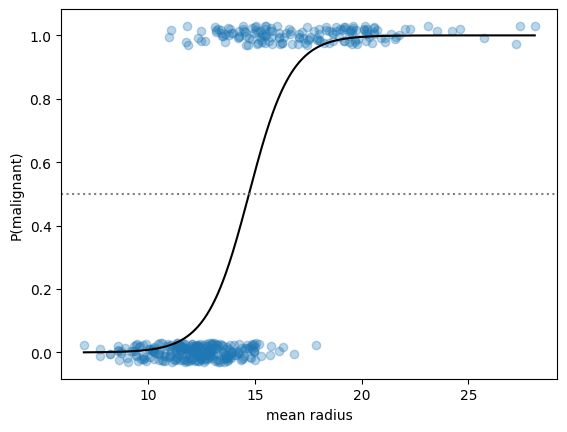

model.coef_:      [[1.01231442]]
model.intercept_: [-14.90225267]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import lr_helpers

cancer = load_breast_cancer()
X = cancer.data[:, [0]]                 # mean radius only, as an (n, 1) array
y = (cancer.target == 0).astype(int)    # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0,
                                                    stratify=y)

model = LogisticRegression()
model.fit(X_train, y_train)

lr_helpers.plot_1d(model, X_train[:, 0], y_train, xlabel='mean radius',
                   ylabel='P(malignant)')
plt.show()
print("model.coef_:     ", model.coef_)
print("model.intercept_:", model.intercept_)

With more than one feature, the model has one weight per feature.  The cell below fits a model to two features, mean radius and mean texture.  The shading shows the model's estimated probability of malignancy, with malignant tumors drawn as red triangles and benign tumors as blue circles.  The heavy black line is the decision boundary, where the estimated probability is .5, and the thin lines are where it is .1 and .9.

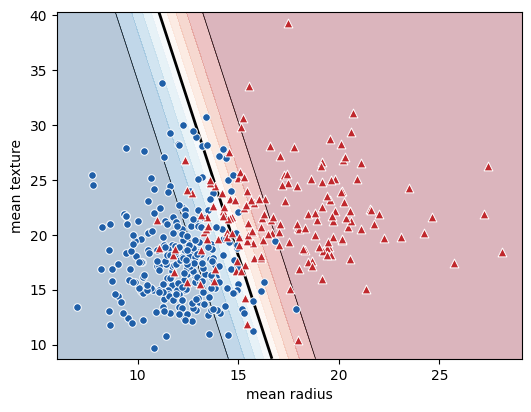

model_2d.coef_:      [[1.01415827 0.18051574]]
model_2d.intercept_: [-18.48513516]


In [2]:
# Same data, but now with two features: mean radius and mean texture.
X_2d = cancer.data[:, [0, 1]]
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d, y, random_state=0, stratify=y)

model_2d = LogisticRegression()
model_2d.fit(X_2d_train, y_2d_train)

plt.figure(figsize=(6, 4.5))
lr_helpers.plot_probabilities(model_2d, X_2d_train, y_2d_train,
                              equal_aspect=False)
plt.xlabel('mean radius')
plt.ylabel('mean texture')
plt.show()
print("model_2d.coef_:     ", model_2d.coef_)
print("model_2d.intercept_:", model_2d.intercept_)

A trained `LogisticRegression` object stores everything it learned in `coef_` and `intercept_`.  Complete the two functions below so that `my_predict_proba` computes the model's estimated probability of the positive class using only those two attributes:

$$\hat{p} = \sigma(\mathbf{w}^\top \mathbf{x} + b) \qquad \text{where} \qquad \sigma(t) = \frac{1}{1 + e^{-t}}$$

Your function should work for any number of features, not just the one we are using here.

In [4]:
def sigmoid(t):
    """ Return the logistic function applied elementwise to t. """
    return 1 / (1 + np.exp(-t))


def my_predict_proba(model, X):
    """ Return a length-n array containing the model's estimated
    probability of the positive class for each row of the (n, d) array X.

    Use only model.coef_ (shape (1, d)) and model.intercept_ (shape (1,)).
    Do not call any of the model's methods.
    """
    weights = model.coef_[0]
    bias = model.intercept_[0]
    t = (X @ weights) + bias
    return sigmoid(t)

In [5]:
## UNIT TESTS

from types import SimpleNamespace
from numpy.testing import assert_allclose

assert_allclose(sigmoid(0), .5)
assert_allclose(sigmoid(np.array([-2., 2.])), [0.11920292, 0.88079708])

# A stand-in that has the learned attributes but none of the methods.
params_only = SimpleNamespace(coef_=model.coef_, intercept_=model.intercept_)
p = my_predict_proba(params_only, X_test)
assert np.shape(p) == (X_test.shape[0],), \
    "Expected a 1-D array of shape {}, got shape {}".format(
        (X_test.shape[0],), np.shape(p))
assert_allclose(p, model.predict_proba(X_test)[:, 1])

# Two features.
two_features = SimpleNamespace(coef_=np.array([[1., -2.]]),
                               intercept_=np.array([.5]))
X_two = np.array([[0., 0.], [1., 1.], [2., -1.]])
assert_allclose(my_predict_proba(two_features, X_two),
                [0.62245933, 0.37754067, 0.98901306])

## Exercise 2 - Cross-Entropy Loss

Training a logistic regression classifier involves finding the $\mathbf{w}$ and $b$ that minimize the cross-entropy, averaged over the training set:

$$J(\mathbf{w}, b) = -\frac{1}{n} \sum_{i=1}^{n} \Big[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \Big]$$

The reading and Scikit-Learn call this the *log loss*, and Scikit-Learn computes it with `sklearn.metrics.log_loss`.  We'll call it by its more common name, **cross-entropy**.

Complete `my_cross_entropy` below without using Scikit-Learn's `log_loss` function.

In [9]:
def my_cross_entropy(y, p):
    """ Return the mean cross-entropy.

    y - array of 0/1 labels
    p - array of estimated probabilities of the positive class
    """
    chunk1 = y * np.log(p)
    chunk2 = (1 - y) * np.log(1 - p)
    return -1 * np.mean(chunk1 + chunk2)

In [10]:
## UNIT TESTS

from sklearn.metrics import log_loss

assert_allclose(my_cross_entropy(np.array([1, 0]), np.array([.9, .2])),
                -(np.log(.9) + np.log(.8)) / 2)

p = model.predict_proba(X_test)[:, 1]
assert_allclose(my_cross_entropy(y_test, p), log_loss(y_test, p))

The cell below compares two hypothetical models on the same five instances.

In [11]:
from sklearn.metrics import log_loss

y_five = np.array([1,   1,   0,   0,   1])
p_a    = np.array([.95, .9,  .05, .1,  .01])
p_b    = np.array([.6,  .6,  .4,  .4,  .45])

for name, p in [('A', p_a), ('B', p_b)]:
    accuracy = np.mean((p >= .5) == y_five)
    print("Model {}:  accuracy {:.2f}   cross-entropy {:.3f}".format(
        name, accuracy, log_loss(y_five, p)))

Model A:  accuracy 0.80   cross-entropy 0.984
Model B:  accuracy 0.80   cross-entropy 0.568


### Questions

* The two models have the same accuracy.  Which one does the cross-entropy prefer, and why?  Do you agree with it?
* In many applications accuracy is what we ultimately care about.  Why train by minimizing the cross-entropy instead of maximizing training accuracy directly?  (Think about what gradient descent needs.)

1) The cross entropy prefers B it gives a lower score for the accumulated penalty. This is because model B is less confident in its predictions. When a model is confidently wrong it gets a bigger penalty. For the situation of cancer diagnosis I agree with this prefrence. I'd rather a model tell me I have a 0.45 percent chance of cancer when I do have it then get overconfident and say theres a 0.01 chance when in fact I do have cancer.
2) Cross-entropy allows us to focus on the percent chance of prediction vs just whether a prediction is right or wrong. If we went soley on accuracy then when we take a small step in gradient decent it could look like no improvement was made because there was no change in accuracy but if we looked at percentages we could see if a models confidence is moving in the right direction a model thats 55% confident about a wrong answer is better then one that 95% confident, even if that doesn't make them different in accuracy. 

## Exercise 3 - When the Data Is Separable

We have been ignoring regularization.  Scikit-Learn's `LogisticRegression` applies an $\ell_2$ penalty by default, so the objective it actually minimizes is

$$\frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^{n} \text{loss}_i$$

where $\|\mathbf{w}\| = \sqrt{\sum_{j=1}^{d} w_j^2}$ is the length (Euclidean norm) of the weight vector and $\text{loss}_i$ is instance $i$'s cross-entropy term.  The bias $b$ is not penalized.  A larger `C` puts more weight on the data and less on keeping $\mathbf{w}$ small, so a larger `C` means *less* regularization.

The value of $\|\mathbf{w}\|$ has a simple geometric meaning.  Before the sigmoid squashes it, the score $t = \mathbf{w}^\top \mathbf{x} + b$ is a plane over the feature space, and $\|\mathbf{w}\|$ is its slope in the steepest direction.  That slope controls how quickly the estimated probability moves from low to high as you cross the decision boundary, so penalizing $\|\mathbf{w}\|^2$ favors a flatter probability surface.

The two classes in the data below can be separated perfectly by a straight line.  The cell fits a model with four different values of `C`.  The shading shows the estimated probability of the red class; the heavy line is the decision boundary, and the thin lines are where the probability is .1 and .9.

**Before running the cell**, predict what will happen to the shading as `C` increases.

C =    0.01:  ||w|| =   0.33   training accuracy 0.983   training cross-entropy 0.47453
C =       1:  ||w|| =   2.43   training accuracy 0.983   training cross-entropy 0.06505
C =     100:  ||w|| =   9.85   training accuracy 1.000   training cross-entropy 0.01330
C =   10000:  ||w|| =  36.40   training accuracy 1.000   training cross-entropy 0.00058


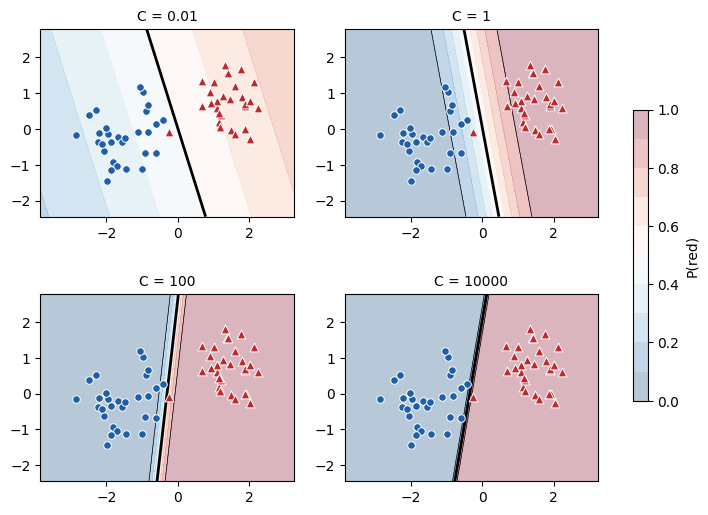

In [12]:
from sklearn.datasets import make_blobs

X2, y2 = make_blobs(n_samples=60, centers=[[-1.5, 0], [1.5, .5]],
                    cluster_std=.6, random_state=3)

Cs = [.01, 1, 100, 10000]
fig, axes = plt.subplots(2, 2, figsize=(9, 6.3))
for C, ax in zip(Cs, axes.ravel()):
    sep_model = LogisticRegression(C=C, max_iter=10000)
    sep_model.fit(X2, y2)
    shading = lr_helpers.plot_probabilities(sep_model, X2, y2, ax=ax,
                                            title="C = {}".format(C))
    print("C = {:>7}:  ||w|| = {:6.2f}   training accuracy {:.3f}   "
          "training cross-entropy {:.5f}".format(
              C, np.linalg.norm(sep_model.coef_), sep_model.score(X2, y2),
              log_loss(y2, sep_model.predict_proba(X2)[:, 1])))
fig.colorbar(shading, ax=axes, shrink=.6, label='P(red)')
plt.show()

### Questions

* As `C` increases, $\|\mathbf{w}\|$ keeps growing while the training accuracy barely changes.  Using what you know about the cross-entropy, explain why.  The reading promises that gradient descent will find the global minimum of the cross-entropy.  With no regularization at all, what value does the training cross-entropy approach on this data, and what happens to $\|\mathbf{w}\|$ as it gets there?
* Would you trust the probabilities produced by the `C = 10000` model on new data?  Why or why not?

1) From the start the line drawn for classification is very accurate. This leaves very little room for the accuracy to improve. However cross entropy can improve because it factors in the models confidence. A model that guesses right and is confident is better then one that guesses right but indicates a high chance of being wrong. Training cross entropy will only be 0 if a model is 100% certain about every point and its correct for every point. Since the model is correctly predicting by increasing **w** we increase confidence. However we will never reach 100% confidence. So as C and **w** increase **w** approaches infinity and the cross entropy approaches 0.
2) No! This may work on training data that happens to be splittable but a model that is predicting confidences close to 100% and 0% every time is not properly factoring in edge cases. If we look at the actual line in the model it is perfectly possible that a new triangle or circle data point would end up on the wrong side of our line. The confidences here are overfitted to the training data. 

## Exercise 4 - What Logistic Regression Can't Do

Run the cell below to fit a logistic regression model to a data set with a curved class boundary.

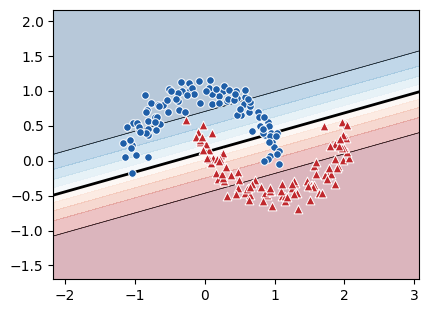

training accuracy: 0.870


In [13]:
from sklearn.datasets import make_moons

X3, y3 = make_moons(n_samples=200, noise=.1, random_state=0)
moon_model = LogisticRegression()
moon_model.fit(X3, y3)

plt.figure(figsize=(5, 3.5))
lr_helpers.plot_probabilities(moon_model, X3, y3)
plt.show()
print("training accuracy: {:.3f}".format(moon_model.score(X3, y3)))

### Question

* A logistic regression classifier can only separate the classes with a straight line (a hyperplane, in more dimensions).  Which of the classification algorithms we have seen so far this semester do not have this limitation?

Decision trees. They can cut out sections along the axis and would be able to fit a curved class boundary. 